<a href="https://colab.research.google.com/github/Temmy-bit/computer-vision-lab/blob/main/Face_Detector.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import cv2
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pip uninstall dlib
pip install dlib --no-cache-dir --verbose
# Or build from source

In [ ]:
import dlib

### Detecting Facial Points

In [ ]:
face_detector = dlib.get_frontal_face_detector()
point_detector = dlib.shape_predictor("/content/drive/MyDrive/Computer Vision Masterclass/Weights/shape_predictor_68_face_landmarks.dat")

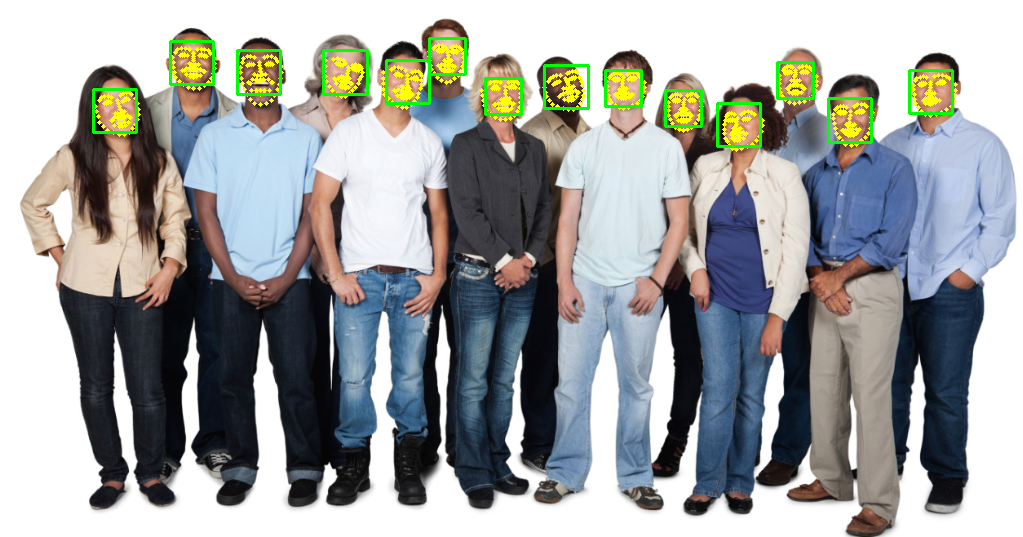

In [ ]:
image = cv2.imread('/content/drive/MyDrive/Computer Vision Masterclass/Images/people2.jpg')

face_detetion = face_detector(image, 1)
for face in face_detetion:
  point = point_detector(image, face)
  # print(point.parts())
  # print(len(point.parts()))
  for p in range(68):
    cv2.circle(image, (point.part(p).x, point.part(p).y), 2, (0, 255, 255), -1)

  l, t, r, b = face.left(), face.top(), face.right(), face.bottom()
  cv2.rectangle(image, (l, t), (r, b), (0, 255, 0), 2)

cv2_imshow(image)

### Detecting Facial Descriptors

In [ ]:
import zipfile
filepath = '/content/drive/MyDrive/Computer Vision Masterclass/Datasets/yalefaces.zip'
zip_object = zipfile.ZipFile(file=filepath,mode='r')
zip_object.extractall('./')
zip_object.close()

In [ ]:
face_detector = dlib.get_frontal_face_detector()
point_detector = dlib.shape_predictor("/content/drive/MyDrive/Computer Vision Masterclass/Weights/shape_predictor_68_face_landmarks.dat")
face_descriptor_extractor = dlib.face_recognition_model_v1("/content/drive/MyDrive/Computer Vision Masterclass/Weights/dlib_face_recognition_resnet_model_v1.dat")
#

In [ ]:
face_descriptor = face_descriptor_extractor.compute_face_descriptor(image_np, points, num_jitters=0)  # already forces CPU in some cases

In [ ]:
index = {}
idx = 0
face_detectors = None

paths = [os.path.join('/content/yalefaces/train', f) for f in os.listdir('/content/yalefaces/train')]

for path in paths:
  # image = cv2.imread(path)
  # print(path)
  image = Image.open(path).convert('RGB')
  image_np = np.array(image,'uint8')
  face_detection = face_detector(image_np, 1)

  for face in face_detection:
    l, t, r, b = face.left(), face.top(), face.right(), face.bottom()
    cv2.rectangle(image_np, (l, t), (r, b), (0, 0, 255), 2)

    points = point_detector(image_np, face)
    for point in points.parts():
      cv2.circle(image_np, (point.x, point.y), 2, (0, 255, 255), -1)

    # face_descriptor = face_descriptor_extractor.compute_face_descriptor(image_np, points)
    face_descriptor = face_descriptor_extractor.compute_face_descriptor(image_np, points, 0) # The 0 argument forces CPU usage
    # print(type(face_descriptor))
  cv2_imshow(image_np)

In [ ]:
probabilities = [0.1, 0.61, 0.001, 0.2, 0.05, 0.0081, 0.0009, 0.03]
sum(probabilities)

1.0